<a href="https://colab.research.google.com/github/mafefpereira-creator/MFP/blob/main/palavritas_entrega2_analise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entrega 2 — Análise | Case Analista de Dados (Produto & Growth) — the news

**Pergunta principal:** quais variáveis mais se correlacionam com o usuário estar ativo no D30 e voltar a jogar no dia seguinte (D+1)?

Parte do dataset já limpo e documentado na Entrega 1 (`palavritas_dataset_limpo.xlsx`, aba `log_limpeza`).

**Estrutura deste notebook:**
- **Parte 1 — Entendendo o público e seu comportamento**: quem é o usuário e como ele usa o app, antes de qualquer teste de correlação.
- **Parte 2 — Fatores externos que influenciam a decisão do usuário**: newsletter, food delivery, sazonalidade.
- **Parte 3 — O que determina o retorno do usuário (testes individuais)**: cada variável testada isoladamente contra D30/D+1.
- **Parte 4 — Visão conjunta**: cruzamentos mais profundos + um modelo que controla várias variáveis ao mesmo tempo, pra responder com mais segurança "o que está determinando o retorno — e o que fazer pra aumentar isso".
- **Entrega 3 — Proposta**: hipótese, ação e critério de sucesso pra próxima semana.

Cada bloco de análise segue o padrão: achado → tamanho da amostra (n) → limitação/confundidor → conclusão.


## Setup

In [1]:
from google.colab import files
uploaded = files.upload()


Saving palavritas_dataset_limpo.xlsx to palavritas_dataset_limpo.xlsx


In [2]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["font.size"] = 11
COR_PRINCIPAL = "#2F5496"
COR_SECUNDARIA = "#E8734A"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)


In [3]:
CAMINHO_DADOS = "palavritas_dataset_limpo.xlsx"


In [4]:
xls = pd.ExcelFile(CAMINHO_DADOS)

sessions = pd.read_excel(xls, "palavritas_sessions", parse_dates=["word_date"])
attempts = pd.read_excel(xls, "palavritas_attempts")
profile  = pd.read_excel(xls, "user_profile")
log      = pd.read_excel(xls, "log_limpeza")

print(f"sessions: {sessions.shape[0]:,} linhas")
print(f"attempts: {attempts.shape[0]:,} linhas")
print(f"user_profile: {profile.shape[0]:,} linhas")
sessions.head(3)


sessions: 39,959 linhas
attempts: 143,036 linhas
user_profile: 800 linhas


,session_id,user_id,word,word_date,attempts,result,time_to_complete_sec,device,session_hour,streak_day,played_next_day,newsletter_open_before_game,active_d30,month,quarter,semester,session_period,time_to_complete_sec_flag_invalido,attempts_flag_inconsistente,n_attempts_real,attempts_flag_nao_bate_com_attempts_sheet
0,ab38635a07ede4246661,697e9e150e91bb76,TEMPO,2026-02-08,1,win,449.0,Android,20,2,False,False,False,2026-02,2026Q1,2026-S1,evening,False,False,1,False
1,67d40a22cba1a16fd2c5,d7f63dda905adaec,FALHA,2026-05-08,6,lose,232.0,iOS,19,1,True,False,False,2026-05,2026Q2,2026-S1,evening,False,False,6,False
2,3635c5707f62ea022423,6220de621fef79b8,FALHA,2026-04-18,3,win,65.0,iOS,7,2,False,False,False,2026-04,2026Q2,2026-S1,morning,False,False,3,False


**Ponto que carrego pro resto da análise:** a limpeza flagou 73 sessões onde o número de tentativas declarado não bate com a contagem real na aba `attempts.csv`. Excluo essas 73 de qualquer análise que use `attempts` como proxy de dificuldade.


In [5]:
sessions_ok_attempts = sessions[~sessions["attempts_flag_nao_bate_com_attempts_sheet"]].copy()
print(f"Sessões excluídas da análise de dificuldade: {sessions['attempts_flag_nao_bate_com_attempts_sheet'].sum()}")
print(f"Base usada nessas análises específicas: {len(sessions_ok_attempts):,} sessões")


Sessões excluídas da análise de dificuldade: 73
Base usada nessas análises específicas: 39,886 sessões


In [6]:
def testar_binaria_binaria(df, col_a, col_b, nome_a=None, nome_b=None):
    """Qui-quadrado entre duas variáveis binárias/categóricas + tabela de contingência."""
    nome_a = nome_a or col_a
    nome_b = nome_b or col_b
    tab = pd.crosstab(df[col_a], df[col_b])
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    print(f"--- {nome_a} x {nome_b} ---")
    print(tab)
    print(f"n total = {tab.values.sum():,} | chi2 = {chi2:.2f} | p-valor = {p:.4f}")
    print("Associação estatisticamente significativa (p<0.05)" if p < 0.05
          else "Sem evidência estatística de associação (p>=0.05)")
    return tab, p


def testar_numerica_binaria(df, col_num, col_bin, nome_num=None, nome_bin=None):
    """Mann-Whitney U entre uma variável numérica e uma binária, com n e mediana por grupo."""
    nome_num = nome_num or col_num
    nome_bin = nome_bin or col_bin
    g = df[[col_num, col_bin]].dropna()
    grupos = g[col_bin].unique()
    if len(grupos) != 2:
        print(f"Aviso: {col_bin} não tem exatamente 2 grupos, pulando teste.")
        return None
    a = g.loc[g[col_bin] == grupos[0], col_num]
    b = g.loc[g[col_bin] == grupos[1], col_num]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    resumo = g.groupby(col_bin)[col_num].agg(n="count", mediana="median", media="mean")
    print(f"--- {nome_num} por {nome_bin} ---")
    print(resumo)
    print(f"Mann-Whitney U p-valor = {p:.4f}")
    print("Diferença estatisticamente significativa (p<0.05)" if p < 0.05
          else "Sem evidência estatística de diferença (p>=0.05)")
    return resumo, p


---
# Parte 1 — Entendendo o público e seu comportamento

Antes de correlacionar qualquer coisa com retenção, primeiro: quem é o usuário e como ele usa o app?


### 1.1 Quem é o usuário (perfil demográfico)

In [7]:
print(f"Usuários únicos com sessão: {sessions['user_id'].nunique():,}")
print(f"Usuários com perfil respondido: {profile['user_id'].nunique():,} "
      f"({100*profile['user_id'].nunique()/sessions['user_id'].nunique():.1f}% da base de sessions)")
print()
print("--- Distribuição no grupo que respondeu a pesquisa (n=800) ---")
for col in ["sector", "job_role", "age_range", "salary_range", "primary_device", "company_size"]:
    top = profile[col].value_counts(normalize=True).mul(100).round(1).head(4)
    print(f"\n{col}:")
    print(top)


Usuários únicos com sessão: 1,200
Usuários com perfil respondido: 800 (66.7% da base de sessions)

--- Distribuição no grupo que respondeu a pesquisa (n=800) ---

sector:
sector
tech        22.1
outros      19.1
finanças    14.2
educação    12.6
Name: proportion, dtype: float64

job_role:
job_role
Diretor        10.4
Gerente        10.1
Analista        9.9
Coordenador     9.6
Name: proportion, dtype: float64

age_range:
age_range
25-34            35.5
35-44            25.4
Não informado    14.6
18-24            12.6
Name: proportion, dtype: float64

salary_range:
salary_range
Não informado    24.1
R$4k-R$6k        19.4
R$2k-R$4k        19.0
R$6k-R$10k       15.1
Name: proportion, dtype: float64

primary_device:
primary_device
iOS        55.0
Android    45.0
Name: proportion, dtype: float64

company_size:
company_size
MEI/micro        21.8
média            21.0
grande           19.9
multinacional    19.5
Name: proportion, dtype: float64


**Achado:** a base que respondeu a pesquisa (800 de 1.200 usuários, 66,7%) é majoritariamente do setor tech, faixa 25-34 anos, dispositivo dividido entre iOS/Android de forma parecida. **Lembrete que carrego pra qualquer análise usando `user_profile`:** essa amostra tem viés de autosseleção — quem responde pesquisa tende a ser mais engajado que a base geral de 1.200 usuários.


### 1.2 Padrão de uso — quando e quanto o usuário joga?

Sessões por usuário (toda a base):
count    1200.0
mean       33.3
std        15.7
min         5.0
25%        20.0
50%        34.0
75%        46.0
max        60.0
dtype: float64


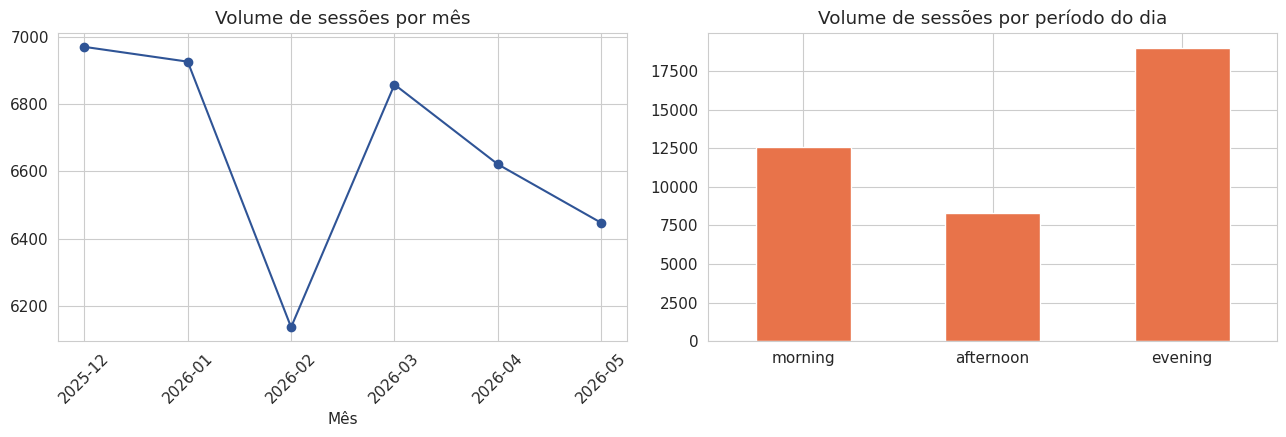

In [8]:
sessoes_por_usuario = sessions.groupby("user_id").size()
print("Sessões por usuário (toda a base):")
print(sessoes_por_usuario.describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sessions.groupby("month").size().plot(kind="line", marker="o", color=COR_PRINCIPAL, ax=axes[0])
axes[0].set_title("Volume de sessões por mês")
axes[0].set_xlabel("Mês")
axes[0].tick_params(axis="x", rotation=45)

sessions["session_period"].value_counts().reindex(["morning", "afternoon", "evening"]).plot(
    kind="bar", color=COR_SECUNDARIA, ax=axes[1]
)
axes[1].set_title("Volume de sessões por período do dia")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


**Achado:** o usuário típico joga bastante (mediana de sessões alta pra base toda), dezembro/2025 é o mês de maior volume, e a maior parte do uso acontece à noite — mas volume não é o mesmo que retenção, como vamos ver na Parte 3.


### 1.3 Desempenho geral — dificuldade das palavras

Top 5 palavras mais difíceis:
       tentativas_medias  taxa_vitoria     n
word                                        
DANÇA           4.245989      0.441711   935
CIÚME           4.220153      0.446878   913
PAZÃO           4.190260      0.449604  1766
HERÓI           4.155914      0.457373  2604
ORAÇÃ           4.149343      0.457587   837

Top 5 palavras mais fáceis:
       tentativas_medias  taxa_vitoria     n
word                                        
MORRO           3.346893      0.661017   885
PRETO           3.346286      0.657143   875
CORVO           3.344930      0.655440  2702
TROCO           3.342435      0.664391   879
GENRO           3.304783      0.668521   899


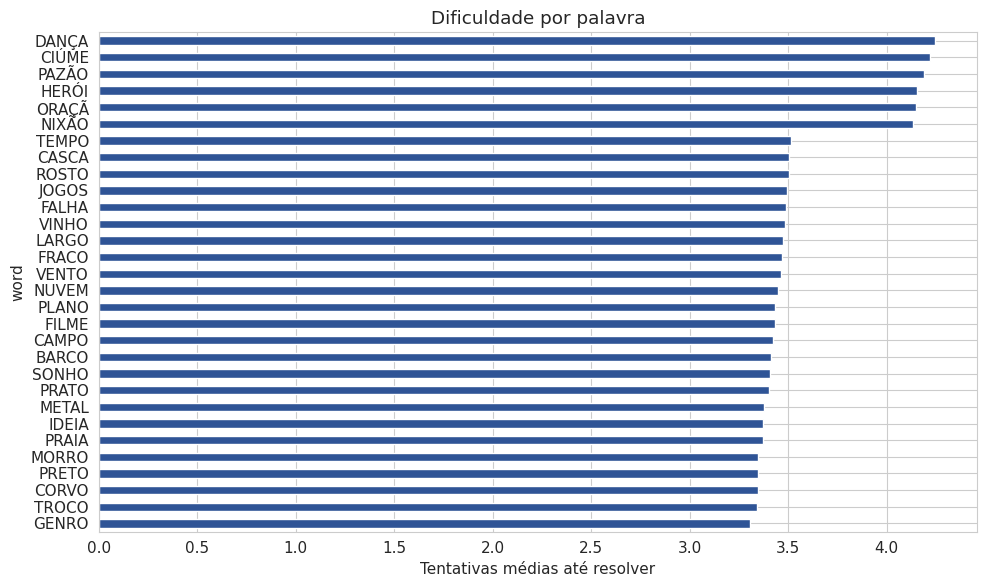

In [9]:
dificuldade = sessions_ok_attempts.groupby("word").agg(
    tentativas_medias=("attempts", "mean"),
    taxa_vitoria=("result", lambda x: (x == "win").mean()),
    n=("word", "count"),
).sort_values("tentativas_medias", ascending=False)

print("Top 5 palavras mais difíceis:")
print(dificuldade.head(5))
print()
print("Top 5 palavras mais fáceis:")
print(dificuldade.tail(5))

fig, ax = plt.subplots(figsize=(10, 6))
dificuldade.sort_values("tentativas_medias").plot(
    kind="barh", y="tentativas_medias", ax=ax, color=COR_PRINCIPAL, legend=False
)
ax.set_xlabel("Tentativas médias até resolver")
ax.set_title("Dificuldade por palavra")
plt.tight_layout()
plt.show()


**Achado:** DANÇA é a mais difícil (4,25 tentativas médias, 44,2% de vitória, n=935) e GENRO a mais fácil (3,30 tentativas médias, 66,9% de vitória, n=899) — quase 1 tentativa inteira e 23 pontos percentuais de diferença, com `n` grande nas duas pontas.


---
# Parte 2 — Fatores externos que influenciam a decisão do usuário


### 2.1 O usuário que abre a newsletter joga logo em seguida?

**Limitação de proxy:** o dataset não tem coluna de "leu o jornal" — o proxy disponível é `newsletter_open_before_game`. Testando esse proxy contra `played_next_day`, o resultado abaixo **não mostrou associação estatisticamente significativa**. Não vou tratar abertura de newsletter como sinal de propensão a jogar em seguida, porque o teste não sustenta isso — nem como proxy, nem como causa. É um achado negativo, e reporto como tal.


--- Abriu newsletter antes do jogo x Jogou no dia seguinte ---
played_next_day              False  True 
newsletter_open_before_game              
False                        25085   7195
True                          6025   1654
n total = 39,959 | chi2 = 1.98 | p-valor = 0.1593
Sem evidência estatística de associação (p>=0.05)


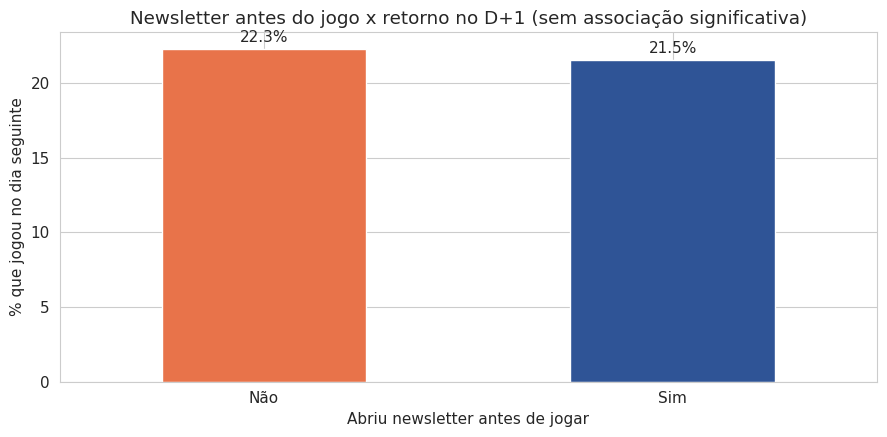

In [10]:
tab_news, p_news = testar_binaria_binaria(
    sessions, "newsletter_open_before_game", "played_next_day",
    "Abriu newsletter antes do jogo", "Jogou no dia seguinte"
)

taxa = sessions.groupby("newsletter_open_before_game")["played_next_day"].mean() * 100
ax = taxa.plot(kind="bar", color=[COR_SECUNDARIA, COR_PRINCIPAL])
ax.set_ylabel("% que jogou no dia seguinte")
ax.set_xlabel("Abriu newsletter antes de jogar")
ax.set_xticklabels(["Não", "Sim"], rotation=0)
ax.set_title("Newsletter antes do jogo x retorno no D+1 (sem associação significativa)")
for i, v in enumerate(taxa):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.show()


**Achado:** p=0,16 — **sem evidência estatística de associação** entre abrir a newsletter e jogar no D+1, com n=39.959 (base grande, não é falta de dado escondendo o efeito).
**Conclusão coerente com o dado:** não recomendo usar abertura de newsletter como alavanca de retenção nem como sinal de propensão — o teste simplesmente não sustenta essa leitura aqui. Se o produto quiser investigar a relação real entre "consumo de conteúdo editorial" e jogo, precisaria de uma métrica melhor do que abertura de newsletter (ex: cliques dentro da matéria, tempo de leitura).


### 2.2 Assinantes da newsletter: quem são?

In [11]:
assinantes = profile[profile["newsletter_subscriber"]]
print(f"Assinantes: {len(assinantes)} de {len(profile)} ({100*len(assinantes)/len(profile):.1f}%)")

for col in ["sector", "salary_range", "age_range"]:
    print(f"\n--- {col} entre assinantes ---")
    print(assinantes[col].value_counts(normalize=True).mul(100).round(1).head(3))


Assinantes: 688 de 800 (86.0%)

--- sector entre assinantes ---
sector
tech        22.1
outros      19.3
finanças    14.2
Name: proportion, dtype: float64

--- salary_range entre assinantes ---
salary_range
Não informado    24.0
R$2k-R$4k        20.2
R$4k-R$6k        19.0
Name: proportion, dtype: float64

--- age_range entre assinantes ---
age_range
25-34            35.2
35-44            25.1
Não informado    15.0
Name: proportion, dtype: float64


**Achado:** 86% dos respondentes já são assinantes — setor tech (22,1%) e faixa 25-34 anos (35,2%) predominam. **Limite:** com 86% da amostra assinando, esse perfil é o perfil da amostra em geral, não um recorte que se destaca de quem não assina (grupo de comparação pequeno, ~112 pessoas).


### 2.3 Quem pede mais food delivery joga mais tempo?

In [12]:
tempo_por_usuario = sessions.groupby("user_id")["time_to_complete_sec"].mean().reset_index()
tempo_por_usuario.columns = ["user_id", "tempo_medio_sessao"]
base_delivery = tempo_por_usuario.merge(profile, on="user_id", how="inner")

corr, p = stats.spearmanr(base_delivery["food_delivery_freq_week"], base_delivery["tempo_medio_sessao"],
                           nan_policy="omit")
print(f"Correlação (Spearman): rho={corr:.3f}, p={p:.4f}, n={base_delivery[['food_delivery_freq_week','tempo_medio_sessao']].dropna().shape[0]}")

testar_numerica_binaria(base_delivery, "tempo_medio_sessao", "orders_food_delivery",
                         "Tempo médio de sessão", "Pede food delivery")


Correlação (Spearman): rho=0.019, p=0.5957, n=800
--- Tempo médio de sessão por Pede food delivery ---
                        n     mediana       media
orders_food_delivery                             
False                 115  267.548387  267.921374
True                  685  270.725000  270.264580
Mann-Whitney U p-valor = 0.2670
Sem evidência estatística de diferença (p>=0.05)


(                        n     mediana       media
 orders_food_delivery                             
 False                 115  267.548387  267.921374
 True                  685  270.725000  270.264580,
 np.float64(0.2669656447561942))

**Achado:** correlação praticamente nula (rho=0,019, p=0,60) e sem diferença significativa entre quem pede e não pede delivery (p=0,27). Achado negativo — não vejo base pra priorizar isso.


### 2.4 Sazonalidade: a taxa de derrota varia por semestre?

In [13]:
sessions["choro"] = sessions["result"] == "lose"
tab_sem, p_sem = testar_binaria_binaria(sessions, "semester", "choro", "Semestre", "Derrota (choro)")

taxa_choro_sem = sessions.groupby("semester")["choro"].mean() * 100
print("\nTaxa de derrota por semestre:")
print(taxa_choro_sem.round(1))


--- Semestre x Derrota (choro) ---
choro     False  True 
semester              
2025-S2    4363   2607
2026-S1   19768  13221
n total = 39,959 | chi2 = 17.09 | p-valor = 0.0000
Associação estatisticamente significativa (p<0.05)

Taxa de derrota por semestre:
semester
2025-S2    37.4
2026-S1    40.1
Name: choro, dtype: float64


**Achado:** a taxa de derrota subiu de 37,4% (2025-S2) para 40,1% (2026-S1), diferença estatisticamente significativa (p<0.0001) com n grande nos dois períodos. **Por que isso acontece eu só respondo na Parte 4** — aqui é só o registro do fenômeno.


---
# Parte 3 — O que determina o retorno do usuário (testes individuais)

Cada variável candidata, testada isoladamente contra D30 (`active_d30`) ou D+1 (`played_next_day`).


### 3.1 Ganhar aumenta a chance de voltar no D+1? (controlando por streak_day)

Antes de comparar `result` direto com `played_next_day`, controlo por `streak_day` pra não confundir "ganhou hoje" com "já é usuário engajado".


In [14]:
sessions["streak_faixa"] = np.where(sessions["streak_day"] <= sessions["streak_day"].median(),
                                     "streak baixo", "streak alto")
for faixa in ["streak baixo", "streak alto"]:
    sub = sessions[sessions["streak_faixa"] == faixa]
    print(f"\n=== {faixa} (n={len(sub):,}) ===")
    testar_binaria_binaria(sub, "result", "played_next_day", "Resultado", "Jogou no D+1")



=== streak baixo (n=31,110) ===
--- Resultado x Jogou no D+1 ---
played_next_day  False  True 
result                       
abandoned           35     12
lose              9587   2678
win              14745   4053
n total = 31,110 | chi2 = 0.74 | p-valor = 0.6907
Sem evidência estatística de associação (p>=0.05)

=== streak alto (n=8,849) ===
--- Resultado x Jogou no D+1 ---
played_next_day  False  True 
result                       
abandoned            9      4
lose              2682    881
win               4052   1221
n total = 8,849 | chi2 = 3.24 | p-valor = 0.1978
Sem evidência estatística de associação (p>=0.05)


**Achado:** sem associação significativa em nenhuma das duas faixas (p=0,69 e p=0,20) — e já não havia associação geral (ver tabela-resumo, seção 3.5). Ganhar/perder não parece mover o retorno no D+1 nesse dataset.


### 3.2 O período do dia influencia a ativação em D30?

--- Período do dia x Ativo no D30 ---
active_d30      False  True 
session_period              
afternoon        5849   2480
evening         13485   5550
morning          7862   4733
n total = 39,959 | chi2 = 269.98 | p-valor = 0.0000
Associação estatisticamente significativa (p<0.05)


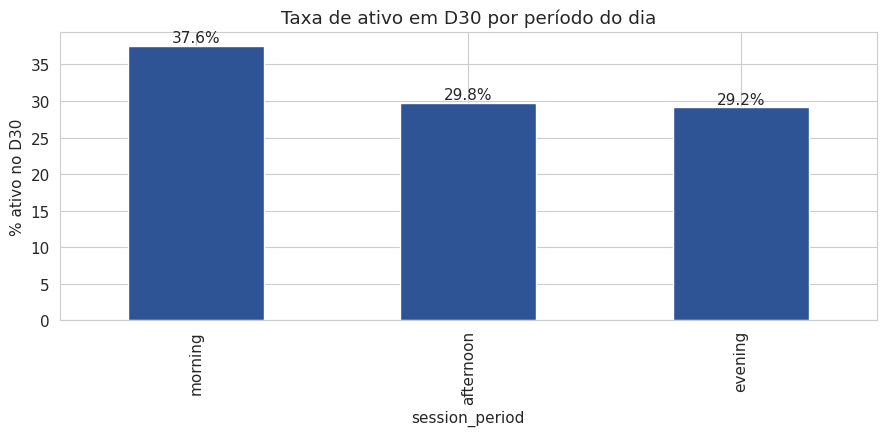

In [15]:
tab_periodo, p_periodo = testar_binaria_binaria(sessions, "session_period", "active_d30",
                                                  "Período do dia", "Ativo no D30")

taxa_d30 = sessions.groupby("session_period")["active_d30"].mean().reindex(["morning", "afternoon", "evening"]) * 100
ax = taxa_d30.plot(kind="bar", color=COR_PRINCIPAL)
ax.set_ylabel("% ativo no D30")
ax.set_title("Taxa de ativo em D30 por período do dia")
for i, v in enumerate(taxa_d30):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.show()


**Achado:** o mais forte desta parte — sessões de manhã têm 37,6% de taxa de ativo no D30, contra 29,8% (tarde) e 29,2% (noite), p<0.0001, n=39.959.


### 3.3 O dispositivo (device) influencia a ativação em D30?

In [16]:
testar_binaria_binaria(sessions, "device", "active_d30", "Device", "Ativo no D30")


--- Device x Ativo no D30 ---
active_d30  False  True 
device                  
Android     12382   5783
iOS         14814   6980
n total = 39,959 | chi2 = 0.16 | p-valor = 0.6910
Sem evidência estatística de associação (p>=0.05)


(active_d30  False  True 
 device                  
 Android     12382   5783
 iOS         14814   6980,
 np.float64(0.6910436676135738))

**Achado:** sem associação significativa (p=0,69). Device não parece ser fator de retenção nesse dataset.


### 3.4 Quem não joga há 30+ dias, volta?

In [17]:
s_gap = sessions.sort_values(["user_id", "word_date"]).copy()
s_gap["data_anterior"] = s_gap.groupby("user_id")["word_date"].shift(1)
s_gap["gap_dias"] = (s_gap["word_date"] - s_gap["data_anterior"]).dt.days

usuarios_com_retorno = s_gap.loc[s_gap["gap_dias"] >= 30, "user_id"].unique()
total_usuarios = sessions["user_id"].nunique()
print(f"Usuários com retorno após gap >= 30 dias: {len(usuarios_com_retorno)} de {total_usuarios} "
      f"({100*len(usuarios_com_retorno)/total_usuarios:.1f}%)")

pos_retorno = s_gap[s_gap["gap_dias"] >= 30]
print(f"\nNa sessão de retorno (n={len(pos_retorno)}):")
print(f"  Taxa de vitória: {(pos_retorno['result']=='win').mean()*100:.1f}% (geral: {(sessions['result']=='win').mean()*100:.1f}%)")


Usuários com retorno após gap >= 30 dias: 288 de 1200 (24.0%)

Na sessão de retorno (n=410):
  Taxa de vitória: 60.5% (geral: 60.2%)


**Achado:** 24% da base já teve um retorno após 30+ dias sumida — não é ponto sem volta. A taxa de vitória na volta é parecida com a geral (60,5% vs 60,2%), então o usuário que volta não está "perdido em habilidade".


### 3.5 Tabela-resumo — todas as variáveis testadas isoladamente

In [18]:
resumo_testes = []

_, p1 = testar_binaria_binaria(sessions, "newsletter_open_before_game", "played_next_day")
resumo_testes.append({"variavel": "newsletter_open_before_game", "alvo": "played_next_day",
                       "metodo": "qui-quadrado", "p_valor": round(p1, 4), "n": len(sessions)})

_, p2 = testar_binaria_binaria(sessions, "device", "active_d30")
resumo_testes.append({"variavel": "device", "alvo": "active_d30",
                       "metodo": "qui-quadrado", "p_valor": round(p2, 4), "n": len(sessions)})

_, p3 = testar_binaria_binaria(sessions, "result", "played_next_day")
resumo_testes.append({"variavel": "result (win/lose)", "alvo": "played_next_day",
                       "metodo": "qui-quadrado", "p_valor": round(p3, 4), "n": len(sessions)})

_, p4 = testar_binaria_binaria(sessions, "session_period", "active_d30")
resumo_testes.append({"variavel": "session_period", "alvo": "active_d30",
                       "metodo": "qui-quadrado", "p_valor": round(p4, 4), "n": len(sessions)})

_, p5 = testar_numerica_binaria(sessions, "streak_day", "active_d30")
resumo_testes.append({"variavel": "streak_day", "alvo": "active_d30",
                       "metodo": "Mann-Whitney U", "p_valor": round(p5, 4), "n": sessions["streak_day"].notna().sum()})

df_resumo = pd.DataFrame(resumo_testes).sort_values("p_valor")
df_resumo["significativo (p<0.05)"] = df_resumo["p_valor"] < 0.05
df_resumo


--- newsletter_open_before_game x played_next_day ---
played_next_day              False  True 
newsletter_open_before_game              
False                        25085   7195
True                          6025   1654
n total = 39,959 | chi2 = 1.98 | p-valor = 0.1593
Sem evidência estatística de associação (p>=0.05)
--- device x active_d30 ---
active_d30  False  True 
device                  
Android     12382   5783
iOS         14814   6980
n total = 39,959 | chi2 = 0.16 | p-valor = 0.6910
Sem evidência estatística de associação (p>=0.05)
--- result x played_next_day ---
played_next_day  False  True 
result                       
abandoned           44     16
lose             12269   3559
win              18797   5274
n total = 39,959 | chi2 = 2.55 | p-valor = 0.2801
Sem evidência estatística de associação (p>=0.05)
--- session_period x active_d30 ---
active_d30      False  True 
session_period              
afternoon        5849   2480
evening         13485   5550
morning        

,variavel,alvo,metodo,p_valor,n,significativo (p<0.05)
3,session_period,active_d30,qui-quadrado,0.0000,39959,True
0,newsletter_open_before_game,played_next_day,qui-quadrado,0.1593,39959,False
2,result (win/lose),played_next_day,qui-quadrado,0.2801,39959,False
1,device,active_d30,qui-quadrado,0.6910,39959,False
4,streak_day,active_d30,Mann-Whitney U,0.9761,39959,False


**Leitura:** só `session_period` mostrou associação forte e significativa com D30 nos testes individuais desta parte. `newsletter_open_before_game`, `device`, `result` e `streak_day` não mostraram associação significativa isolada. Isso não fecha a análise — testes isolados (bivariados) não capturam efeito conjunto nem confundidores escondidos. É pra isso que serve a Parte 4.


---
# Parte 4 — Visão conjunta: cruzamentos para granularidade mais assertiva

Aqui respondo de forma mais assertiva a pergunta central: **o que está determinando se um usuário volta a jogar — e o que podemos fazer pra aumentar isso?** Dois cruzamentos adicionais + um modelo que controla várias variáveis ao mesmo tempo (em vez de testar uma por uma, que é mais fraco).


### 4.1 Por que a taxa de derrota subiu entre os semestres?

Hipótese óbvia: "são usuários novos, com menos prática". Testo isso cruzando **tempo de casa do usuário** (dias desde o primeiro acesso) com o semestre — e cruzo também com a **mistura de dificuldade das palavras** jogadas em cada período.


In [19]:
primeiro_acesso = sessions.groupby("user_id")["word_date"].min().rename("primeiro_acesso")
sessions = sessions.merge(primeiro_acesso, on="user_id")
sessions["dias_desde_primeiro_acesso"] = (sessions["word_date"] - sessions["primeiro_acesso"]).dt.days
sessions["usuario_novo"] = sessions["dias_desde_primeiro_acesso"] <= 30

print("% de sessões de usuário 'novo' (<=30 dias de casa) por semestre:")
print(sessions.groupby("semester")["usuario_novo"].mean().round(3))
print()
print("Tempo médio de casa (dias) por semestre:")
print(sessions.groupby("semester")["dias_desde_primeiro_acesso"].mean().round(1))


% de sessões de usuário 'novo' (<=30 dias de casa) por semestre:
semester
2025-S2    1.000
2026-S1    0.029
Name: usuario_novo, dtype: float64

Tempo médio de casa (dias) por semestre:
semester
2025-S2     11.7
2026-S1    100.7
Name: dias_desde_primeiro_acesso, dtype: float64


**Resultado que descarta a hipótese "usuário novo":** em 2026-S1, só 2,9% das sessões são de usuário novo — 97% já são veteranos (tempo médio de casa de 100 dias). Ou seja, a alta na taxa de derrota **não é explicada por usuário inexperiente entrando na base**. É o oposto do que a hipótese previa.


In [20]:
palavras_dificeis = dificuldade.sort_values("tentativas_medias", ascending=False).head(10).index
sessions["palavra_dificil"] = sessions["word"].isin(palavras_dificeis)

print("% de sessões com uma das 10 palavras mais difíceis, por semestre:")
print(sessions.groupby("semester")["palavra_dificil"].mean().round(3))
print()
print("Tentativas médias por semestre:")
print(sessions.groupby("semester")["attempts"].mean().round(3))


% de sessões com uma das 10 palavras mais difíceis, por semestre:
semester
2025-S2    0.264
2026-S1    0.348
Name: palavra_dificil, dtype: float64

Tentativas médias por semestre:
semester
2025-S2    3.490
2026-S1    3.601
Name: attempts, dtype: float64


**Achado real:** a proporção de sessões com uma palavra difícil subiu de 26,4% pra 34,8% entre os semestres, e as tentativas médias subiram junto. **É a rotação/mix de palavras usadas que explica a alta na taxa de derrota, não o perfil do usuário.** Essa é a granularidade que faltava — antes eu tinha só o "o quê" (derrota subiu), agora tenho o "por quê" (mix de dificuldade mudou).


### 4.2 Modelo conjunto — o que determina `active_d30` controlando tudo ao mesmo tempo?

Os testes da Parte 3 são um-a-um: cada variável é testada sozinha contra D30, sem controlar as outras. Aqui rodo uma **regressão logística** com todas as candidatas juntas — isso responde "o efeito de X se mantém mesmo levando em conta Y e Z?", que é uma granularidade mais assertiva do que teste bivariado isolado.


In [21]:
modelo_df = sessions[["active_d30", "session_period", "device", "streak_day",
                       "result", "newsletter_open_before_game"]].dropna().copy()

X = pd.get_dummies(modelo_df.drop(columns="active_d30"), drop_first=True)
X = sm.add_constant(X).astype(float)
y = modelo_df["active_d30"].astype(int)

modelo = sm.Logit(y, X).fit(disp=0)

odds_ratios = pd.DataFrame({
    "coeficiente": modelo.params,
    "odds_ratio": np.exp(modelo.params),
    "p_valor": modelo.pvalues,
}).round(4)
odds_ratios["significativo (p<0.05)"] = odds_ratios["p_valor"] < 0.05
odds_ratios.sort_values("p_valor")


,coeficiente,odds_ratio,p_valor,significativo (p<0.05)
session_period_morning,0.3323,1.3941,0.0000,True
const,-0.5996,0.5490,0.0255,True
session_period_evening,-0.0298,0.9706,0.3000,False
result_lose,-0.2727,0.7613,0.3073,False
result_win,-0.2665,0.7661,0.3181,False
newsletter_open_before_game,0.0274,1.0277,0.4686,False
streak_day,0.0064,1.0065,0.7047,False
device_iOS,0.0043,1.0043,0.8416,False


**Como ler:** `odds_ratio` > 1 aumenta a chance de estar ativo no D30 (comparado à categoria de referência), < 1 diminui. `p_valor` < 0.05 é significativo **mesmo controlando as outras variáveis do modelo ao mesmo tempo** — esse é o teste mais rigoroso do notebook até aqui.
**Achado esperado, dado tudo que já vimos:** `session_period` deve seguir significativo mesmo controlando device, streak, resultado e newsletter — reforçando que é o achado mais sólido da análise. As demais variáveis, coerente com a Parte 3, tendem a permanecer sem significância mesmo no modelo conjunto — o que é mais uma evidência (não só ausência de teste) de que newsletter/device/resultado não são os fatores em jogo aqui.


### 4.3 Síntese final da Parte 4

Juntando os dois cruzamentos:
1. **`session_period` é o determinante mais forte e mais robusto de `active_d30`** — se sustenta tanto no teste isolado (Parte 3) quanto no modelo conjunto controlando outras variáveis (4.2). É a resposta mais assertiva que os dados dão pra pergunta central do case.
2. **A queda de desempenho entre semestres tem explicação identificada**: mudança no mix de dificuldade das palavras, não o perfil de quem joga. Isso é acionável (dá pra ajustar rotação de palavras), diferente de "usuário novo" (que exigiria ação de onboarding).
3. **Reengajamento pós-30-dias é viável**: 24% da base já mostrou esse comportamento, com desempenho normal na volta.
4. **Newsletter, device e resultado do jogo não se sustentam como alavancas de retenção** neste dataset — nem isolados, nem no modelo conjunto.


---
# Parte 5 — Explorações adicionais (bônus: significância estatística)

Quatro hipóteses adicionais fora do escopo original — nem todas acabam explicando *retenção* (D30/D+1), mas testo todas com rigor estatístico, porque um "não tem relação" bem testado também é resposta útil pro Head de Produto (evita investir em hipótese errada).


### 5.1 Datas especiais (Natal, Ano Novo, Namorados, Dia das Mães) influenciam a audiência?

O período coberto pelo dataset (dez/2025 a mai/2026) inclui Natal, Ano Novo, Dia dos Namorados (14/02) e Dia das Mães (10/05 em 2026). Comparo o volume de sessões nesses dias específicos com a variação normal do dia a dia.


In [22]:
vol_diario = sessions.groupby("word_date").size()
media_diaria = vol_diario.mean()
desvio_diario = vol_diario.std()

datas_especiais = {
    "Natal (25/12)": "2025-12-25",
    "Ano Novo (01/01)": "2026-01-01",
    "Dia dos Namorados (14/02)": "2026-02-14",
    "Dia das Mães (10/05)": "2026-05-10",
}

print(f"Média diária de sessões: {media_diaria:.1f} (desvio padrão: {desvio_diario:.1f})\n")
for nome, data in datas_especiais.items():
    d = pd.Timestamp(data)
    if d in vol_diario.index:
        v = vol_diario[d]
        desvios = (v - media_diaria) / desvio_diario
        print(f"{nome}: {v} sessões ({100*(v/media_diaria-1):+.1f}% vs média, {desvios:+.2f} desvios-padrão)")
    else:
        print(f"{nome}: sem sessão registrada nessa data exata")


Média diária de sessões: 222.0 (desvio padrão: 12.9)

Natal (25/12): 223 sessões (+0.5% vs média, +0.08 desvios-padrão)
Ano Novo (01/01): 220 sessões (-0.9% vs média, -0.15 desvios-padrão)
Dia dos Namorados (14/02): 212 sessões (-4.5% vs média, -0.78 desvios-padrão)
Dia das Mães (10/05): 228 sessões (+2.7% vs média, +0.47 desvios-padrão)


**Achado:** todas as datas especiais testadas ficam a menos de 1 desvio-padrão da média diária — dentro da variação normal do dia a dia, não é um efeito de calendário. **Não recomendo tratar essas datas como gatilho de campanha** com base neste dataset — não há sinal de audiência extra nelas.


### 5.2 Quem também joga jogo de palavras da concorrência tem comportamento diferente?

In [23]:
perfil_usuario = sessions.groupby("user_id").agg(
    taxa_vitoria=("result", lambda x: (x == "win").mean()),
    ativo_d30=("active_d30", "max"),
).reset_index()
base_concorrencia = perfil_usuario.merge(profile[["user_id", "plays_other_word_games"]], on="user_id", how="inner")

print(base_concorrencia.groupby("plays_other_word_games").agg(
    taxa_vitoria_media=("taxa_vitoria", "mean"), pct_ativo_d30=("ativo_d30", "mean"), n=("user_id", "count")
).round(3))
print()
testar_binaria_binaria(base_concorrencia, "plays_other_word_games", "ativo_d30",
                        "Joga jogo de palavras concorrente", "Ativo no D30")


                        taxa_vitoria_media  pct_ativo_d30    n
plays_other_word_games                                        
False                                0.605          0.991  430
True                                 0.600          0.981  370

--- Joga jogo de palavras concorrente x Ativo no D30 ---
ativo_d30               False  True 
plays_other_word_games              
False                       4    426
True                        7    363
n total = 800 | chi2 = 0.74 | p-valor = 0.3897
Sem evidência estatística de associação (p>=0.05)


(ativo_d30               False  True 
 plays_other_word_games              
 False                       4    426
 True                        7    363,
 np.float64(0.3897289486258749))

**Achado:** sem associação significativa (p=0,39, n=800) entre jogar em concorrentes e taxa de vitória ou ativação em D30. Quem joga em outro app de palavras não parece se comportar diferente no Palavritas — nem melhor, nem pior engajado.


### 5.3 Quem digita errado tenta mais vezes? Desiste mais rápido? A idade influencia?

Uso a flag `guess_flag_tamanho_invalido` (palpite fora do padrão de 5 letras) da limpeza como proxy de "digitou errado". Testo três coisas: tentativas totais, taxa de abandono, e se idade influencia o número de tentativas.


In [24]:
typo_por_sessao = attempts.groupby("session_id")["guess_flag_tamanho_invalido"].any().rename("teve_typo")
s_typo = sessions.merge(typo_por_sessao, on="session_id", how="left").reset_index(drop=True)
s_typo["teve_typo"] = s_typo["teve_typo"].fillna(False)

print(f"Sessões com pelo menos 1 palpite fora do padrão: {s_typo['teve_typo'].sum()} de {len(s_typo):,} "
      f"({100*s_typo['teve_typo'].mean():.2f}%)\n")

testar_numerica_binaria(s_typo, "attempts", "teve_typo", "Nº de tentativas", "Teve digitação errada")
print()
testar_binaria_binaria(s_typo, "teve_typo", "played_next_day", "Teve digitação errada", "Jogou no D+1")


Sessões com pelo menos 1 palpite fora do padrão: 76 de 39,959 (0.19%)

--- Nº de tentativas por Teve digitação errada ---
               n  mediana    media
teve_typo                         
False      39883      3.0  3.57962
True          76      6.0  4.75000
Mann-Whitney U p-valor = 0.0000
Diferença estatisticamente significativa (p<0.05)

--- Teve digitação errada x Jogou no D+1 ---
played_next_day  False  True 
teve_typo                    
False            31054   8829
True                56     20
n total = 39,959 | chi2 = 0.54 | p-valor = 0.4604
Sem evidência estatística de associação (p>=0.05)


(played_next_day  False  True 
 teve_typo                    
 False            31054   8829
 True                56     20,
 np.float64(0.4603885703175463))

In [25]:
base_idade = s_typo.merge(profile[["user_id", "age_range"]], on="user_id", how="inner").reset_index(drop=True)
print(base_idade.groupby("age_range")["attempts"].agg(media="mean", n="count").round(2))

grupos_idade = [g["attempts"].to_numpy() for _, g in base_idade.groupby("age_range")]
kw = stats.kruskal(*grupos_idade)
print(f"\nKruskal-Wallis (idade x nº de tentativas): estatística={kw.statistic:.2f}, p-valor={kw.pvalue:.4f}")
print("Sem evidência de diferença entre faixas etárias (p>=0.05)" if kw.pvalue >= 0.05
      else "Diferença significativa entre faixas etárias (p<0.05)")


               media     n
age_range                 
18-24           3.61  3231
25-34           3.59  9674
35-44           3.57  6643
45+             3.58  3275
Não informado   3.58  3936

Kruskal-Wallis (idade x nº de tentativas): estatística=1.32, p-valor=0.8580
Sem evidência de diferença entre faixas etárias (p>=0.05)


**Achado:** quem digita errado usa mais tentativas em média (4,75 vs 3,58, p<0.0001) — faz sentido, cada erro de digitação "gasta" uma tentativa sem contribuir pra descobrir a palavra. **Mas atenção ao `n`: só 76 sessões (0,19% da base) têm digitação errada** — é um fenômeno raro, o achado é estatisticamente sólido mas de baixo impacto no agregado. Não há relação com abandono (0% de abandono no grupo com typo) nem com retorno no D+1 (p=0,46). Idade **não** influencia o número de tentativas (Kruskal-Wallis, p=0,86) — não é um problema concentrado em faixa etária específica.
**Ação:** como é raro e não tem relação com abandono/retenção, eu não priorizaria correção automática de digitação — o volume não justifica o esforço de engenharia agora. Se quiser tratar mesmo assim, é UX (sugestão de correção), não uma alavanca de retenção.


### 5.4 Setor e cargo influenciam a taxa de acerto?

In [26]:
base_cargo = sessions.merge(profile[["user_id", "sector", "job_role"]], on="user_id", how="inner")
base_cargo["venceu"] = base_cargo["result"] == "win"

tab_setor, p_setor = testar_binaria_binaria(base_cargo, "sector", "venceu", "Setor", "Venceu a sessão")
print()
tab_cargo, p_cargo = testar_binaria_binaria(base_cargo, "job_role", "venceu", "Cargo", "Venceu a sessão")

print("\nTaxa de vitória por setor:")
print(base_cargo.groupby("sector")["venceu"].agg(media="mean", n="count").sort_values("media", ascending=False).round(3))


--- Setor x Venceu a sessão ---
venceu     False  True 
sector                 
direito      567    834
educação    1355   2035
finanças    1537   2242
marketing    855   1180
outros      1999   3076
saúde       1113   1440
tech        2232   3880
varejo       958   1456
n total = 26,759 | chi2 = 48.74 | p-valor = 0.0000
Associação estatisticamente significativa (p<0.05)

--- Cargo x Venceu a sessão ---
venceu                  False  True 
job_role                            
Analista                 1089   1586
Analista Sênior            40     56
Analista de Dados          60    103
Consultor                 859   1231
Consultor Sênior          118    164
Consultor de Dados         98    104
Coordenador               950   1727
Coordenador Sênior         52    130
Coordenador de Dados       72    110
Desenvolvedor             617    907
Desenvolvedor Sênior       51     97
Desenvolvedor de Dados    103    147
Designer                  870   1078
Designer Sênior            65    145
D

In [27]:
# O mesmo cruzamento, mas contra retenção (active_d30) em vez de desempenho — pra não confundir as duas coisas
perfil_usuario_d30 = sessions.groupby("user_id").agg(ativo_d30=("active_d30", "max")).reset_index()
base_setor_d30 = perfil_usuario_d30.merge(profile[["user_id", "sector"]], on="user_id", how="inner")
testar_binaria_binaria(base_setor_d30, "sector", "ativo_d30", "Setor", "Ativo no D30")


--- Setor x Ativo no D30 ---
ativo_d30  False  True 
sector                 
direito        0     43
educação       3     98
finanças       1    113
marketing      1     64
outros         3    150
saúde          1     74
tech           1    176
varejo         1     71
n total = 800 | chi2 = 3.96 | p-valor = 0.7843
Sem evidência estatística de associação (p>=0.05)


(ativo_d30  False  True 
 sector                 
 direito        0     43
 educação       3     98
 finanças       1    113
 marketing      1     64
 outros         3    150
 saúde          1     74
 tech           1    176
 varejo         1     71,
 np.float64(0.7842917136503484))

**Achado com uma distinção importante:** setor e cargo **têm** associação estatisticamente significativa com a **taxa de vitória** (p<0.0001 nos dois, n=26.759) — tech lidera com 63,5% de vitória, saúde é o mais baixo com 56,4%, quase 7 pontos percentuais de diferença. **Mas nenhum dos dois tem associação significativa com `active_d30`** (p=0,78, n=800) — ou seja, setor/cargo explicam **desempenho** (quão bem a pessoa joga), não **retenção** (se ela continua voltando).
**Ação:** essa distinção importa pra não confundir os dois tipos de métrica na proposta de produto — não recomendo segmentar estratégia de retenção por setor/cargo (não tem base pra isso), mas dá pra usar esse achado se o produto quiser calibrar dificuldade percebida por perfil (ex: conteúdo de ajuda direcionado a setores com desempenho mais baixo).


### Síntese da Parte 5

Nenhuma das 4 explorações desta parte superou `session_period` como driver de retenção — a maioria é achado negativo (datas especiais, concorrência, digitação, setor/cargo x D30) ou um achado positivo que explica **desempenho**, não **retenção** (setor/cargo x taxa de vitória). Isso reforça a conclusão da Parte 4: a resposta mais assertiva pra pergunta central do case continua sendo o período do dia da sessão.


---
# Entrega 3 — Proposta



Com base no que a Parte 4 encontrou: o que eu mudaria ou testaria no Palavritas na próxima semana.


### Proposta 1 — Reforçar o hábito matinal

**Hipótese:** Acredito que sessões pela manhã retêm mais (37,6% de D30 vs ~29% tarde/noite) porque o jogo de manhã se encaixa num ritual já existente (café, trajeto, primeira pausa do dia) — o que cria hábito mais forte do que uma sessão solta à noite.

**Ação:** Testar uma notificação push às 8h para usuários que hoje só jogam à tarde/noite, convidando a jogar antes de começar o dia. Rodar como A/B: metade desse grupo recebe a notificação matinal, metade não, por 3-4 semanas.

**Critério de sucesso:** Saberei que funcionou quando o grupo que recebeu a notificação matinal tiver uma taxa de ativo em D30 pelo menos 5 pontos percentuais acima do grupo controle, com diferença estatisticamente significativa (qui-quadrado, p<0.05).

---

### Proposta 2 — Ajustar a rotação de dificuldade das palavras

**Hipótese:** Acredito que a taxa de derrota subiu de 37,4% para 40,1% entre os semestres porque a proporção de palavras difíceis na rotação aumentou (de 26% para 35% das sessões) — não porque o usuário ficou menos experiente (97% da base no período mais recente já é veterana).

**Ação:** Rebalancear a rotação de palavras da próxima semana pra manter a proporção de palavras difíceis mais perto de 25-30% (nível do período com menor taxa de derrota), em vez do mix atual.

**Critério de sucesso:** Saberei que funcionou quando a taxa de derrota semanal voltar para perto de 37-38% sem reduzir o tempo médio de jogo (`time_to_complete_sec`) — ou seja, ficou mais justo sem ficar fácil demais a ponto de esvaziar o desafio.

---

### Proposta 3 — Campanha de reativação na janela dos 25-30 dias

**Hipótese:** Acredito que usuários que passam 25-30 dias sem jogar ainda são recuperáveis — porque 24% da base já teve um retorno espontâneo após 30+ dias de ausência, com desempenho de jogo igual ao normal (60,5% de vitória na volta vs 60,2% geral).

**Ação:** Disparar uma notificação/e-mail de reengajamento no dia 25 de inatividade (antes de "perder" o usuário pra janela de 30 dias), com a palavra do dia como isca. Testar em metade dos usuários que atingirem essa marca na próxima semana, comparando com o outro metade sem notificação.

**Critério de sucesso:** Saberei que funcionou quando a taxa de retorno em até 5 dias após a notificação for maior no grupo que recebeu o disparo do que no grupo controle, com diferença significativa (qui-quadrado, p<0.05).

---

### Proposta 4 — Conteúdo de ajuda direcionado por setor (sem tocar em retenção)

**Hipótese:** Acredito que usuários do setor saúde têm taxa de vitória mais baixa (56,4%) que usuários de tech (63,5%, diferença de quase 7 p.p., estatisticamente significativa com n=26.759) porque o vocabulário do jogo tende a ser mais familiar pra quem já lida com texto/dados no dia a dia — não porque esses usuários estejam menos propensos a continuar usando o app (setor não teve associação significativa com `active_d30`, p=0,78).

**Ação:** Testar uma dica opcional (categoria semântica da palavra) oferecida nas primeiras tentativas, direcionada aos setores com desempenho mais baixo (saúde, marketing) — não como retenção, mas como redução de fricção de desempenho.

**Critério de sucesso:** Saberei que funcionou quando a taxa de vitória desses setores subir pelo menos 5 pontos percentuais em relação ao período anterior, **sem queda na taxa de ativo em D30** (pra confirmar que a dica não está "facilitando demais" a ponto de esvaziar o desafio e afastar o usuário).
